In [1]:
from data_pipeline.fetch_all_team_data import fetch_all_team_data

"""
main jupyter notebook for Ml project]
Ronan kenny 
23404724
"""

'\nmain jupyter notebook for Ml project]\nRonan kenny \n23404724\n'

In [2]:

# use module to load in the total team data and extract match statistics for all teams
from pathlib import Path
import pandas as pd
from data_pipeline.fetch_all_team_data import fetch_all_team_data

data_path = Path("../data/all_match_stats.csv")

if data_path.exists():
    all_match_stats = pd.read_csv(data_path)
    print(f"Loaded cached data from {data_path}")
else:
    all_match_stats = fetch_all_team_data()
    data_path.parent.mkdir(parents=True, exist_ok=True)
    all_match_stats.to_csv(data_path, index=False)
    print(f"Fetched and saved data to {data_path}")
    
#all_match_stats = fetch_all_team_data()


Loaded cached data from ../data/all_match_stats.csv


In [3]:
from data_pipeline.consolidate_data_fields import consolidate_data_fields

# use helper function to consolodate duplicate stats 
# that may be stored in different names but represent the same data
all_match_stats = consolidate_data_fields(all_match_stats)

# possession either stored as 0.67 or 67 
# handle different methods of storing possession stat 
mask = all_match_stats["possession"] > 1
all_match_stats.loc[mask, "possession"] /= 100


In [4]:
from data_pipeline.filter_rows_with_required_data import filter_rows_with_required_data

required_columns = [
    "tries",
    "kicks_from_hand",
    #"kick_percent_success",
    #"territory",
    #"possession",
    #"22m_entries",
]

model_candidate_data = filter_rows_with_required_data(all_match_stats, required_columns)



In [5]:

from data_pipeline.create_target_col import create_target_col
filtered_dataset = create_target_col(model_candidate_data)

target_distribution = filtered_dataset['high_tries_scored'].value_counts(normalize=True).round(3)
print(f" target distribution : {target_distribution}")


 target distribution : high_tries_scored
0    0.592
1    0.408
Name: proportion, dtype: float64


In [6]:
# Declaring stuff to be used in pipelines below
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression


# update string date values to date object for filtering and split
filtered_dataset['game_date'] = pd.to_datetime(filtered_dataset['game_date'], format='%Y%m%d')
filtered_dataset['year'] = filtered_dataset['game_date'].dt.year

# potential feature cols
extended_feature_columns = [
    "kicks_from_hand",
    "kick_percent_success",
    "territory",
    "possession",
    "22m_entries",
]

#feature_cols = ["kicks_from_hand"] # main training feature

feature_cols = extended_feature_columns

years = sorted(filtered_dataset['year'].unique())
min_train_years = 3


                                      

In [7]:
# Dummy model Pipeline
from data_pipeline.walk_forward_validation import walk_forward_validation



# define sci-kit learn pipeline 
# my dataset is missing some values so I will use imputer for these values in the pipeline - prevents leakagfe
dummy_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('model', DummyClassifier(strategy='prior'))
])

threshold = 0.5

dummy_results = walk_forward_validation(filtered_dataset= filtered_dataset, pipeline=dummy_pipeline, feature_cols=feature_cols, custom_threshold=threshold, min_train_years=min_train_years)

i =0
for res in dummy_results:
    print(f"Fold {i}:   Evaluation Metrics: {res['evaluation_metrics']} ")
    i += 1

dummy_pipeline

Fold 0:   Evaluation Metrics: {'accuracy': 0.5595353339787028, 'precision': 0.0, 'recall': 0.0, 'f1_score': 0.0, 'roc_auc': 0.5} 
Fold 1:   Evaluation Metrics: {'accuracy': 0.46859903381642515, 'precision': 0.0, 'recall': 0.0, 'f1_score': 0.0, 'roc_auc': 0.5} 


/home/ronan/college_work/4th year/machine learning/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/ronan/college_work/4th year/machine learning/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](5,)","['kicks_from_hand','kick_percent_success','territory','possession', '22m_entries']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or ob

Fold 0:   Evaluation Metrics: {'accuracy': 0.5827686350435625, 'precision': 0.5253164556962026, 'recall': 0.5472527472527473, 'f1_score': 0.5360602798708288, 'roc_auc': 0.6332978440244876} 
Fold 1:   Evaluation Metrics: {'accuracy': 0.5942028985507246, 'precision': 0.6074380165289256, 'recall': 0.6681818181818182, 'f1_score': 0.6363636363636364, 'roc_auc': 0.6236029756326148} 


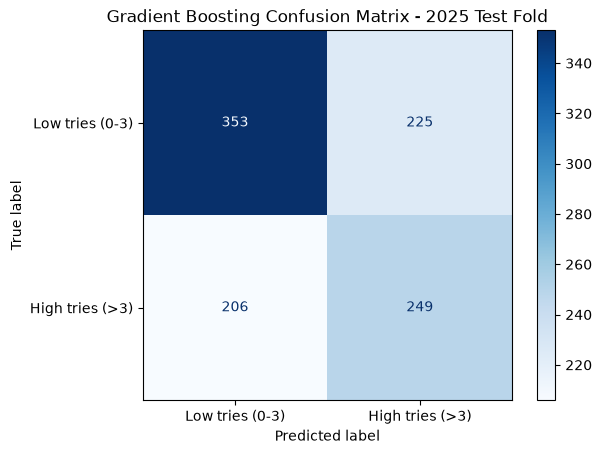

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](5,)","['kicks_from_hand','kick_percent_success','territory','possession', '22m_entries']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string

In [8]:
#Logistic Regression classifier model 
from data_pipeline.walk_forward_validation import walk_forward_validation
from data_pipeline.generate_confusion_matrix import generate_confusion_matrix 

logreg_pipeline = Pipeline(steps =[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('model' , LogisticRegression(
        max_iter=1000,
        class_weight={0: 1.0, 1: 1.5},
        C=1.0
        )
     )
])

threshold = 0.5 # standard threshold 

log_reg_results = walk_forward_validation(filtered_dataset= filtered_dataset, pipeline=logreg_pipeline, custom_threshold=threshold, feature_cols=feature_cols, min_train_years=min_train_years)

i =0
for res in log_reg_results:
    print(f"Fold {i}:   Evaluation Metrics: {res['evaluation_metrics']} ")
    i += 1
generate_confusion_matrix(log_reg_results[0]['confusion_matrix'])

logreg_pipeline


Fold 0:   Evaluation Metrics: {'model__class_weight': 'balanced', 'model__max_depth': 5, 'model__n_estimators': 50} 
Fold 1:   Evaluation Metrics: {'model__class_weight': 'balanced', 'model__max_depth': 5, 'model__n_estimators': 50} 


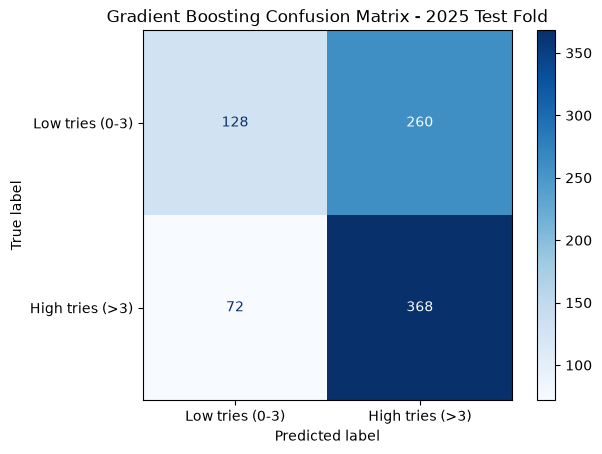

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto account for

In [42]:
# Model Ranbom Forest Classifier

from sklearn.ensemble import RandomForestClassifier

rf_tuning_params = {
        'model__n_estimators': [50, 100, 200],
        'model__max_depth': [5, 8, 10],
        'model__class_weight': [
            'balanced',
            {0: 1.0, 1: 1.4}, 
            {0: 1.0, 1: 1.6},
            {0: 1.2, 1: 1.0},
            {0: 1.4, 1: 1.0}
            ],
    }


random_forest_pipeline = Pipeline(steps =[
    ('imputer', SimpleImputer(strategy='median')),
    ('model' , RandomForestClassifier(n_estimators=100,
                                    class_weight='balanced',
                                    random_state=42,
                                    max_depth=8
                                       ))
])

# lower threshold to catch more positive cases
threshold = 0.45

rf_results = walk_forward_validation(
    filtered_dataset= filtered_dataset,
    pipeline=random_forest_pipeline,
    custom_threshold=threshold,
    feature_cols=feature_cols, 
    min_train_years=min_train_years,
    tuning_params=rf_tuning_params
    
    )
('scaler', StandardScaler()),


i =0
for res in rf_results:
    print(f"Fold {i}:   Evaluation Metrics: {res['tuned_params']} ")
    i += 1

generate_confusion_matrix(rf_results[1]['confusion_matrix'])


random_forest_pipeline 

Fold 0:   Evaluation Metrics: {'model__class_weight': 'balanced', 'model__learning_rate': 0.035, 'model__max_depth': 3, 'model__max_iter': 200} 
Fold 1:   Evaluation Metrics: {'model__class_weight': 'balanced', 'model__learning_rate': 0.03, 'model__max_depth': 5, 'model__max_iter': 200} 


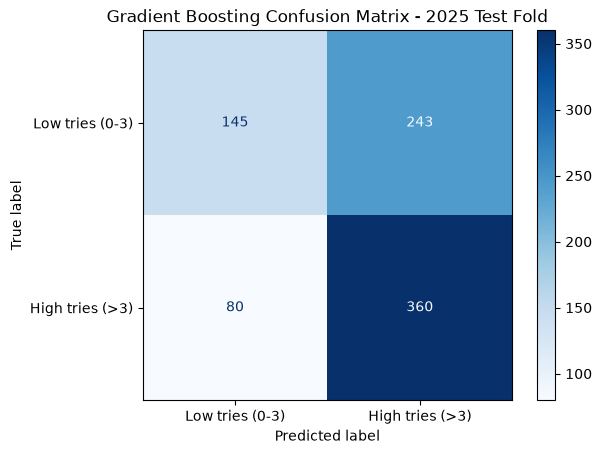

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto account for

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier, HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

gb_tuning_params = {
    'model__max_iter': [100, 150, 200],
    'model__learning_rate': [0.02, 0.03, 0.035],
    'model__max_depth': [3, 4, 5],
    'model__class_weight': [
        'balanced',
        {0: 1.0, 1: 1.4}, 
        {0: 1.0, 1: 1.6},
        {0: 1.4, 1: 1.0}
    ]
}


gradient_boosting_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("model", HistGradientBoostingClassifier(
        max_iter=220,
        learning_rate=0.035,
        max_depth=5,
        min_samples_leaf=25,
        l2_regularization=1.5,
        random_state=42,
        class_weight='balanced',
        
    ))
])
# lower the decision threshold to catch more positive cases 
threshold = 0.45

gb_results = walk_forward_validation(
    filtered_dataset=filtered_dataset,
    pipeline=gradient_boosting_pipeline,
    feature_cols=feature_cols,
    min_train_years=min_train_years,
    custom_threshold=threshold,
    tuning_params=gb_tuning_params
)

i =0
for res in gb_results:
    #print(f"Fold {i}:   Evaluation Metrics: {res['evaluation_metrics']} ")
    print(f"Fold {i}:   Evaluation Metrics: {res['tuned_params']} ")

    #print(f"Fold {i}:   Evaluation Metrics: f1:{res['evaluation_metrics']['f1_score']}, accuracy: {res['evaluation_metrics']['accuracy']} ")
    i += 1

generate_confusion_matrix(gb_results[1]['confusion_matrix'])

gradient_boosting_pipeline


In [50]:
# Compare all models in one fold-level metrics table
model_results = {
    "Dummy baseline": dummy_results,
    "Logistic regression": log_reg_results,
    "Random forest": rf_results,
    "Gradient boosting": gb_results,
}

comparison_rows = []
for model_name, fold_results in model_results.items():
    for result in fold_results:
        metrics = result["evaluation_metrics"]
        comparison_rows.append({
            "Model": model_name,
            "Test year": int(result["test_year"]),
            "Train rows": result["train_size"],
            "Test rows": result["test_size"],
            "Accuracy": metrics["accuracy"],
            "Precision": metrics["precision"],
            "Recall": metrics["recall"],
            "F1": metrics["f1_score"],
            "ROC-AUC": metrics["roc_auc"],
        })

results_table = pd.DataFrame(comparison_rows)
metric_columns = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
results_table[metric_columns] = results_table[metric_columns].round(3)
results_table

,Model,Test year,Train rows,Test rows,Accuracy,Precision,Recall,F1,ROC-AUC
0,Dummy baseline,2025,4204,1033,0.560,0.000,0.000,0.000,0.500
1,Dummy baseline,2026,5237,828,0.469,0.000,0.000,0.000,0.500
2,Logistic regression,2025,4204,1033,0.583,0.525,0.547,0.536,0.633
3,Logistic regression,2026,5237,828,0.594,0.607,0.668,0.636,0.624
4,Random forest,2025,4204,1033,0.577,0.512,0.868,0.644,0.667
5,Random forest,2026,5237,828,0.599,0.586,0.836,0.689,0.653
6,Gradient boosting,2025,4204,1033,0.582,0.515,0.857,0.644,0.681
7,Gradient boosting,2026,5237,828,0.610,0.597,0.818,0.690,0.656


In [51]:
from data_pipeline.get_top_errors import get_top_errors

get_top_errors(results =gb_results, fold_year=2026, num_errors=30)


error_type
correct           505
false positive    243
false negative     80
Name: count, dtype: int64


,game_date,match_id,team,team_id,team_vs,tries,kicks_from_hand,kick_percent_success,territory,possession,22m_entries,actual,predicted,probability_high_tries,error_type
109,2026-01-16,ef51441d,Pau,34bd3e4e,Bulls,3.0,29.0,NaN,NaN,0.66,5.0,0,1,0.850700,false positive
110,2026-01-24,fc9ea817,Pau,34bd3e4e,Toulouse,3.0,19.0,NaN,NaN,0.43,12.0,0,1,0.596973,false positive
112,2026-02-22,e0144ffd,Pau,34bd3e4e,Perpignan,3.0,26.0,NaN,NaN,0.43,7.0,0,1,0.487799,false positive
115,2026-03-28,9f6ebf2e,Pau,34bd3e4e,Racing 92,3.0,26.0,NaN,NaN,0.69,12.0,0,1,0.756296,false positive
279,2026-01-11,e147a6cd,Toulon,94c0327a,Munster,3.0,30.0,NaN,NaN,0.63,6.0,0,1,0.634990,false positive
286,2026-03-28,d835771a,Toulon,94c0327a,Perpignan,3.0,16.0,NaN,NaN,0.51,14.0,0,1,0.720783,false positive
366,2026-02-22,0641a6bf,France,67d88578,Italy,5.0,29.0,NaN,NaN,0.52,8.0,1,0,0.433753,false negative
408,2026-02-21,1f72d392,Ireland,165b36e5,England,5.0,31.0,NaN,NaN,0.48,9.0,1,0,0.449858,false negative
444,2026-03-06,6274ea68,Italy U20,bf499d89,England U20,3.0,22.0,NaN,NaN,0.41,12.0,0,1,0.665431,false positive
447,2026-07-02,cd04f30a,Italy U20,bf499d89,Japan U20,6.0,24.0,NaN,NaN,0.38,8.0,1,0,0.335806,false negative
